# Brasileirão Série A 2026 — análise de rebaixamento

Notebook para apresentação: tratamento do `BRA.csv`, validação contra os marts dbt e gráficos interativos das probabilidades e das cinco últimas edições completas.

**Premissas:** o CSV tem resultados até 20/10/2026. Os adversários e mandos restantes são inferidos pelo turno e returno (sem datas). A média histórica é referência, não garantia.

In [1]:
from pathlib import Path
import os
import duckdb
import numpy as np
import pandas as pd
import plotly.express as px
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / 'BRA.csv').exists():
    ROOT = ROOT.parent
CSV_PATH = ROOT / 'BRA.csv'
DB_PATH = Path(os.getenv('DB_PATH', str(ROOT / 'warehouse' / 'football.duckdb')))
if not DB_PATH.is_absolute():
    DB_PATH = ROOT / DB_PATH
assert CSV_PATH.exists(), f'CSV não encontrado: {CSV_PATH}'
assert DB_PATH.exists(), f'Warehouse não encontrado; rode o pipeline: {DB_PATH}'
print(f'CSV: {CSV_PATH}\nDuckDB: {DB_PATH}')

CSV: C:\Users\User\Desktop\dados-futebol\BRA.csv
DuckDB: C:\Users\User\Desktop\dados-futebol\warehouse\football.duckdb


## 1. Tratamento e validação dos resultados
Filtramos a temporada e divisão, tipamos datas e gols e removemos registros sem placar. Depois derivamos a classificação a partir de linhas por time (mando e visitante).

In [2]:
source = pd.read_csv(CSV_PATH, encoding='utf-8-sig')
source.columns = source.columns.str.strip()
matches = source.loc[
    source['League'].astype(str).str.strip().str.casefold().eq('serie a')
    & source['Season'].astype(str).str.strip().eq('2026')
].copy()
matches['Date'] = pd.to_datetime(matches['Date'], dayfirst=True, errors='coerce')
for col in ['HG', 'AG']:
    matches[col] = pd.to_numeric(matches[col], errors='coerce')
matches = matches.dropna(subset=['Date', 'Home', 'Away', 'HG', 'AG']).copy()
matches[['HG', 'AG']] = matches[['HG', 'AG']].astype(int)
print(f'{len(source):,} linhas no CSV; {len(matches):,} resultados válidos em 2026')
print(f"Último resultado: {matches['Date'].max():%d/%m/%Y}")
display(matches[['Date', 'Home', 'HG', 'AG', 'Away']].tail(8).reset_index(drop=True))

5,629 linhas no CSV; 309 resultados válidos em 2026
Último resultado: 20/10/2026


,Date,Home,HG,AG,Away
0,2026-10-17,Atletico-MG,1,0,Coritiba
1,2026-10-17,Athletico-PR,0,2,Palmeiras
2,2026-10-18,Sao Paulo,1,0,Vasco
3,2026-10-18,Fluminense,1,2,Santos
4,2026-10-18,Gremio,2,4,Cruzeiro
5,2026-10-18,Bahia,0,3,Flamengo RJ
6,2026-10-18,Remo,1,1,Bragantino
7,2026-10-20,Corinthians,1,1,Vitoria


In [3]:
def team_rows(df, is_home):
    team_col, gf_col, ga_col = ('Home', 'HG', 'AG') if is_home else ('Away', 'AG', 'HG')
    out = pd.DataFrame({
        'team': df[team_col], 'played': 1,
        'wins': (df[gf_col] > df[ga_col]).astype(int),
        'draws': (df[gf_col] == df[ga_col]).astype(int),
        'losses': (df[gf_col] < df[ga_col]).astype(int),
        'goals_for': df[gf_col], 'goals_against': df[ga_col],
    })
    out['points'] = 3 * out['wins'] + out['draws']
    return out

team_results = pd.concat([team_rows(matches, True), team_rows(matches, False)], ignore_index=True)
clean_table = team_results.groupby('team', as_index=False).sum(numeric_only=True)
clean_table['goal_difference'] = clean_table['goals_for'] - clean_table['goals_against']
clean_table = clean_table.sort_values(
    ['points', 'wins', 'goal_difference', 'goals_for', 'team'],
    ascending=[False, False, False, False, True]).reset_index(drop=True)
clean_table.insert(0, 'position', np.arange(1, len(clean_table) + 1))
display(clean_table.head(10))

,position,team,played,wins,draws,losses,goals_for,goals_against,points,goal_difference
0,1,Flamengo RJ,31,20,7,4,61,25,67,36
1,2,Palmeiras,31,19,9,3,54,22,66,32
2,3,Athletico-PR,31,15,8,8,49,37,53,12
3,4,Cruzeiro,31,15,6,10,50,46,51,4
4,5,Fluminense,31,14,9,8,49,39,51,10
5,6,Atletico-MG,31,14,8,9,42,35,50,7
6,7,Bahia,31,13,10,8,44,39,49,5
7,8,Santos,31,12,9,10,48,46,45,2
8,9,Sao Paulo,31,12,6,13,36,35,42,1
9,10,Bragantino,31,11,8,12,39,36,41,3


## 2. Warehouse, probabilidades e pontos históricos
A tabela calculada acima é comparada com `mart_current_standings`. As outras consultas leem os marts dbt, mantendo a mesma fonte de verdade usada pela API.

In [4]:
conn = duckdb.connect(str(DB_PATH), read_only=True)
try:
    mart_table = conn.execute("select position, team, played, wins, draws, losses, goals_for, goals_against, goal_difference, points from mart_current_standings where season='2026' and league='BRA' order by position").df()
    thresholds = conn.execute("select season, last_safe_team, last_safe_points, last_relegated_team, last_relegated_points from mart_historical_relegation_thresholds where league='BRA' order by season").df()
    relegated = conn.execute("select season, relegated_team, final_position, points from mart_historical_relegated_teams where league='BRA' order by season desc, final_position").df()
    risk = conn.execute("with latest as (select max(estimated_at) as latest_at from mart_relegation_estimates where season='2026' and league='BRA') select e.team, e.position, e.points, e.relegation_probability, e.simulations, e.estimated_at from mart_relegation_estimates e join latest l on e.estimated_at=l.latest_at where e.season='2026' and e.league='BRA' order by e.relegation_probability desc").df()
    risk_history = conn.execute("select team, estimated_at, relegation_probability from mart_relegation_estimates where season='2026' and league='BRA'").df()
    remaining_count = conn.execute("select count(*) from int_remaining_fixtures where season='2026' and league='BRA'").fetchone()[0]
finally:
    conn.close()

compare = clean_table.merge(mart_table, on='team', suffixes=('_csv', '_dbt'))
for col in ['played', 'wins', 'draws', 'losses', 'goals_for', 'goals_against', 'goal_difference', 'points']:
    assert (compare[f'{col}_csv'] == compare[f'{col}_dbt']).all(), f'Divergência: {col}'
assert len(compare) == 20 and len(thresholds) == 5 and remaining_count == 71
print(f'Validação OK: 20 times, {remaining_count} confrontos restantes e 5 temporadas históricas.')
display(mart_table)

Validação OK: 20 times, 71 confrontos restantes e 5 temporadas históricas.


,position,team,played,wins,draws,losses,goals_for,goals_against,goal_difference,points
0,1,Flamengo RJ,31.0,20.0,7.0,4.0,61.0,25.0,36.0,67.0
1,2,Palmeiras,31.0,19.0,9.0,3.0,54.0,22.0,32.0,66.0
2,3,Athletico-PR,31.0,15.0,8.0,8.0,49.0,37.0,12.0,53.0
3,4,Cruzeiro,31.0,15.0,6.0,10.0,50.0,46.0,4.0,51.0
4,5,Fluminense,31.0,14.0,9.0,8.0,49.0,39.0,10.0,51.0
5,6,Atletico-MG,31.0,14.0,8.0,9.0,42.0,35.0,7.0,50.0
6,7,Bahia,31.0,13.0,10.0,8.0,44.0,39.0,5.0,49.0
7,8,Santos,31.0,12.0,9.0,10.0,48.0,46.0,2.0,45.0
8,9,Sao Paulo,31.0,12.0,6.0,13.0,36.0,35.0,1.0,42.0
9,10,Bragantino,31.0,11.0,8.0,12.0,39.0,36.0,3.0,41.0


In [5]:
safe_avg = float(thresholds['last_safe_points'].mean())
relegated_avg = float(thresholds['last_relegated_points'].mean())
display(Markdown(f'**Média do 16º (último salvo): {safe_avg:.1f} pts**  \\n**Média do 17º (último rebaixado): {relegated_avg:.1f} pts**  \\nMeta histórica indicativa: **{np.ceil(safe_avg):.0f} pontos**.'))
risk['risk_pct'] = 100 * risk['relegation_probability']
risk[['team', 'position', 'points', 'risk_pct', 'simulations']].head(10)

**Média do 16º (último salvo): 43.8 pts**  \n**Média do 17º (último rebaixado): 41.6 pts**  \nMeta histórica indicativa: **44 pontos**.

,team,position,points,risk_pct,simulations
0,Chapecoense-SC,20,18.0,100.000,20000
1,Remo,19,26.0,99.155,20000
2,Gremio,18,31.0,78.310,20000
3,Internacional,17,32.0,50.810,20000
4,Corinthians,16,33.0,37.410,20000
5,Mirassol,14,36.0,12.950,20000
6,Vasco,15,35.0,11.550,20000
7,Vitoria,13,37.0,5.060,20000
8,Coritiba,12,39.0,3.180,20000
9,Botafogo RJ,11,39.0,1.460,20000


## Exportar para o carrossel do LinkedIn
O LinkedIn não executa os gráficos interativos do Plotly. Rode a célula seguinte para gerar imagens PNG e um PDF de cinco páginas para publicar como documento/carrossel; mantenha o notebook como link para exploração interativa.

In [6]:
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

EXPORT_DIR = ROOT / 'reports' / 'linkedin'
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
PDF_PATH = EXPORT_DIR / 'brasileirao_2026_carrossel.pdf'
plt.rcParams.update({'font.size': 12, 'axes.titlesize': 18, 'figure.titlesize': 22})

def save_slide(fig, name, pdf):
    fig.tight_layout(rect=[0.05, 0.05, 0.95, 0.93])
    fig.savefig(EXPORT_DIR / f'{name}.png', dpi=180, bbox_inches='tight', facecolor='white')
    pdf.savefig(fig, bbox_inches='tight', facecolor='white')
    plt.close(fig)

with PdfPages(PDF_PATH) as pdf:
    # 1 — Capa e contexto
    fig, ax = plt.subplots(figsize=(8, 10)); ax.axis('off')
    ax.text(.05, .88, 'BRASILEIRÃO 2026', transform=ax.transAxes, fontsize=30, weight='bold', color='#17324d')
    ax.text(.05, .79, 'Risco de rebaixamento', transform=ax.transAxes, fontsize=23, color='#e76f51')
    ax.text(.05, .64, f'{len(matches)} resultados analisados\n{remaining_count} confrontos restantes inferidos\n20.000 simulações Monte Carlo', transform=ax.transAxes, fontsize=18, linespacing=1.8)
    ax.text(.05, .41, f'Média do 16º salvo: {safe_avg:.1f} pontos\nMédia do 17º rebaixado: {relegated_avg:.1f} pontos\nHistórico: edições completas de 2021 a 2025', transform=ax.transAxes, fontsize=15, linespacing=1.8, color='#17324d')
    ax.text(.05, .14, 'Estimativas, não garantias. O CSV não informa datas futuras; os confrontos e mandos restantes foram inferidos pelo turno e returno.', transform=ax.transAxes, fontsize=11, wrap=True, color='#555555')
    save_slide(fig, '01_capa', pdf)

    # 2 — Dez maiores riscos
    top = risk.nlargest(10, 'relegation_probability').sort_values('relegation_probability')
    fig, ax = plt.subplots(figsize=(8, 10))
    colors = ['#d9534f' if p >= .5 else '#f0ad4e' if p >= .2 else '#5cb85c' for p in top['relegation_probability']]
    bars = ax.barh(top['team'], top['relegation_probability']*100, color=colors)
    ax.set_xlim(0, 110); ax.set_xlabel('Probabilidade estimada (%)'); ax.set_title('Times com maior risco estimado')
    ax.grid(axis='x', alpha=.2)
    for bar, p in zip(bars, top['relegation_probability']): ax.text(bar.get_width()+1, bar.get_y()+bar.get_height()/2, f'{p:.1%}', va='center')
    save_slide(fig, '02_maiores_riscos', pdf)

    # 3 — Cortes de pontos históricos
    x = np.arange(len(thresholds)); width = .36
    fig, ax = plt.subplots(figsize=(8, 10))
    ax.bar(x-width/2, thresholds['last_safe_points'], width, label='16º — último salvo', color='#2a9d8f')
    ax.bar(x+width/2, thresholds['last_relegated_points'], width, label='17º — último rebaixado', color='#e76f51')
    ax.set_xticks(x, thresholds['season']); ax.set_ylabel('Pontos'); ax.set_title('Cortes históricos — cinco edições')
    ax.legend(); ax.grid(axis='y', alpha=.2)
    save_slide(fig, '03_cortes_historicos', pdf)

    # 4 — Pontos dos quatro rebaixados
    relegated_pivot = relegated.pivot(index='season', columns='final_position', values='points').sort_index()
    fig, ax = plt.subplots(figsize=(8, 10))
    relegated_pivot.rename(columns={17:'17º', 18:'18º', 19:'19º', 20:'20º'}).plot(kind='bar', ax=ax, color=['#e76f51','#f4a261','#457b9d','#264653'])
    ax.set_xlabel('Temporada'); ax.set_ylabel('Pontos'); ax.set_title('Pontuação dos quatro rebaixados')
    ax.legend(title='Posição final'); ax.grid(axis='y', alpha=.2); ax.tick_params(axis='x', rotation=0)
    save_slide(fig, '04_pontos_rebaixados', pdf)

    # 5 — Pontos atuais versus referência histórica
    bottom = mart_table.sort_values('position').tail(10).sort_values('points')
    fig, ax = plt.subplots(figsize=(8, 10))
    bars = ax.barh(bottom['team'], bottom['points'], color='#457b9d')
    ax.axvline(safe_avg, color='#e76f51', linestyle='--', linewidth=2, label=f'Média do 16º: {safe_avg:.1f} pts')
    ax.set_xlabel('Pontos atuais'); ax.set_title('Pontuação dos dez times na parte inferior'); ax.legend(); ax.grid(axis='x', alpha=.2)
    for bar in bars: ax.text(bar.get_width()+.5, bar.get_y()+bar.get_height()/2, f'{bar.get_width():.0f}', va='center')
    save_slide(fig, '05_pontos_vs_referencia', pdf)

print(f'PDF para LinkedIn: {PDF_PATH}')
print(f'PNGs individuais: {EXPORT_DIR}')

# Static PNG fallbacks for notebook hosts that do not render Plotly MIME.
fig, ax = plt.subplots(figsize=(8, 10))
colors = ['#d9534f' if p >= .5 else '#f0ad4e' if p >= .2 else '#5cb85c' for p in risk['relegation_probability']]
ax.scatter(risk['points'], risk['relegation_probability'] * 100, c=colors, s=100, edgecolor='white')
for _, row in risk.iterrows():
    ax.annotate(row['team'], (row['points'], row['relegation_probability'] * 100), xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.set_xlabel('Pontos atuais'); ax.set_ylabel('Probabilidade de rebaixamento (%)')
ax.set_title('Pontos atuais ? risco estimado'); ax.grid(alpha=.2)
fig.savefig(EXPORT_DIR / '06_pontos_vs_risco.png', dpi=180, bbox_inches='tight', facecolor='white')
plt.close(fig)

history_team = risk.iloc[0]['team']
history_series = risk_history.loc[risk_history['team'].eq(history_team)].sort_values('estimated_at')
if len(history_series) > 1:
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(history_series['estimated_at'], history_series['relegation_probability'] * 100, marker='o', color='#457b9d')
    ax.set_ylabel('Probabilidade de rebaixamento (%)'); ax.set_title(f'Evolu??o do risco ? {history_team}')
    ax.grid(alpha=.2); fig.autofmt_xdate()
    fig.savefig(EXPORT_DIR / '07_evolucao_risco.png', dpi=180, bbox_inches='tight', facecolor='white')
    plt.close(fig)


PDF para LinkedIn: C:\Users\User\Desktop\dados-futebol\reports\linkedin\brasileirao_2026_carrossel.pdf
PNGs individuais: C:\Users\User\Desktop\dados-futebol\reports\linkedin


## 3. Gráficos interativos

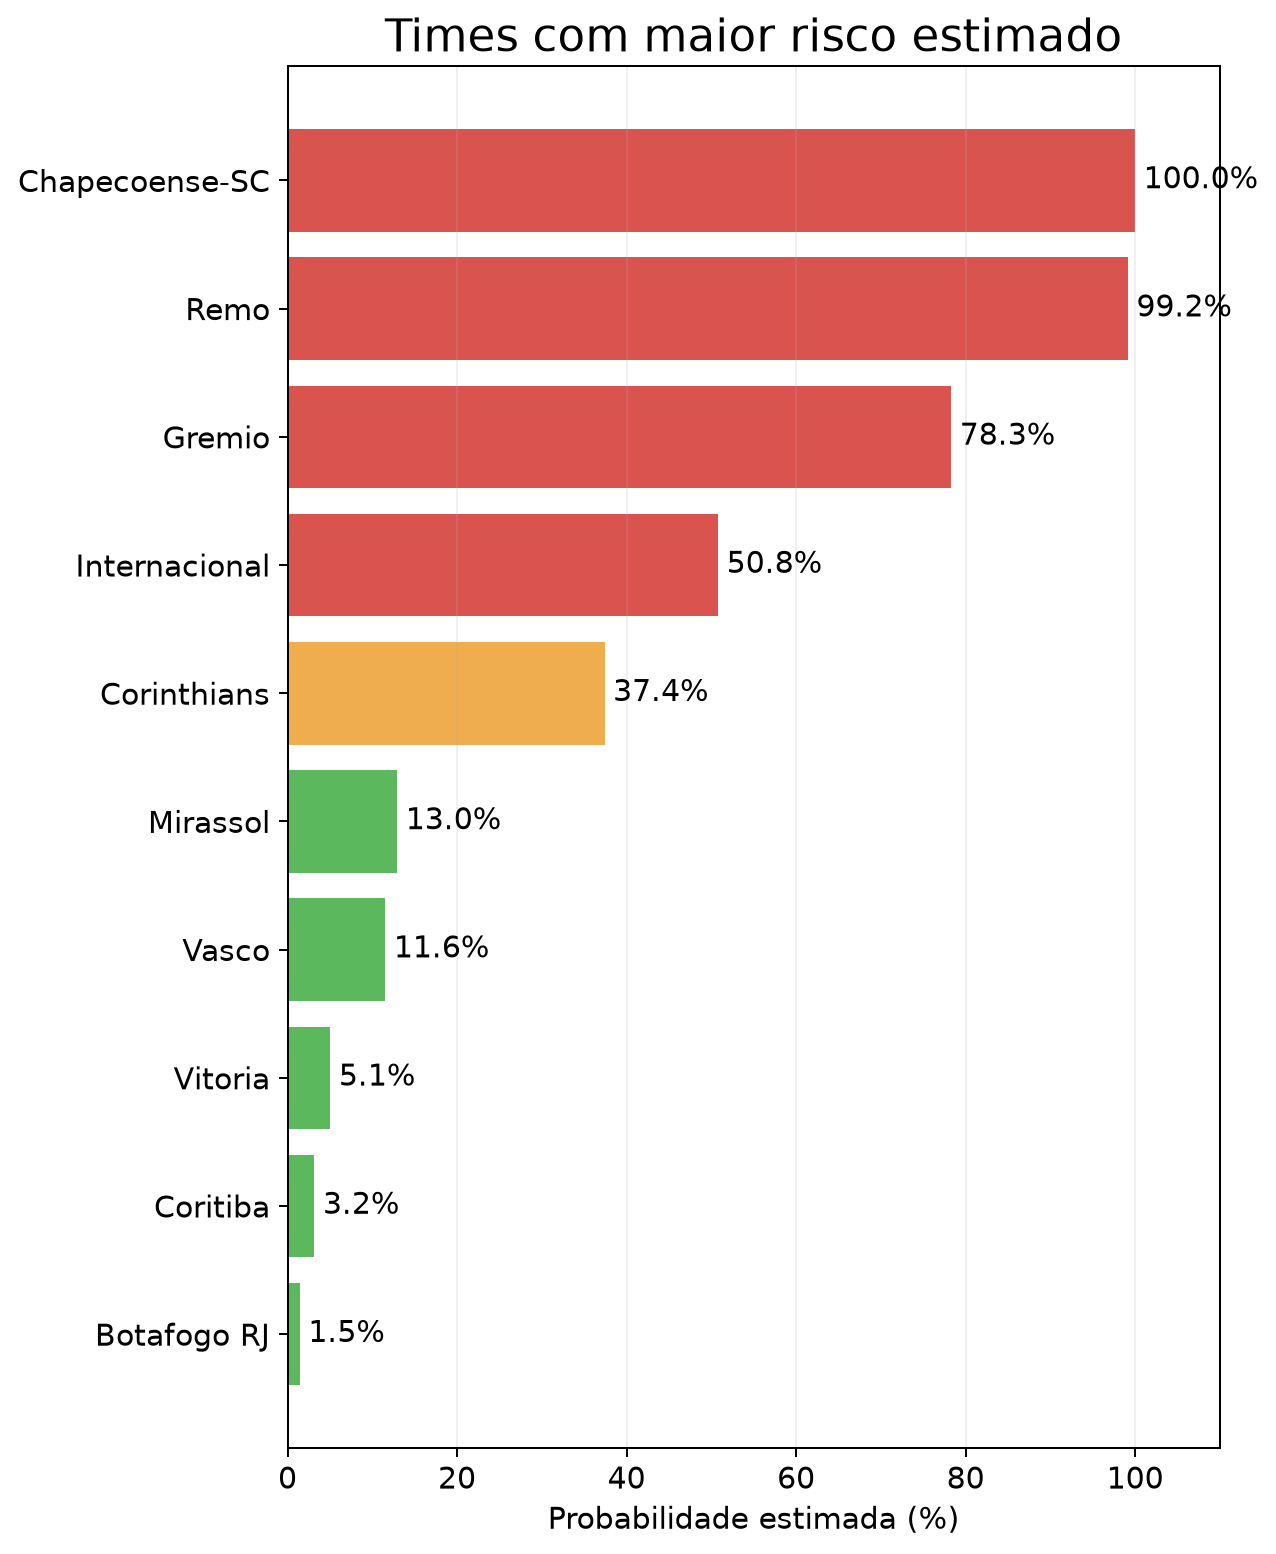

In [7]:
risk_plot = risk.sort_values('relegation_probability')
fig = px.bar(risk_plot, x='relegation_probability', y='team', orientation='h',
    text=risk_plot['relegation_probability'].map(lambda x: f'{x:.0%}'),
    color='relegation_probability', color_continuous_scale='RdYlGn_r',
    hover_data={'position': True, 'points': True, 'simulations': True, 'relegation_probability': ':.1%'},
    labels={'team':'Time', 'relegation_probability':'Risco estimado', 'position':'Posição', 'points':'Pontos'},
    title='Probabilidade estimada de rebaixamento — Brasileirão 2026', template='plotly_white')
fig.update_layout(height=650, yaxis={'categoryorder':'total ascending'}, coloraxis_showscale=False)
fig.update_traces(textposition='outside', cliponaxis=False)
fig.show()
display(Image(filename=str(EXPORT_DIR / '02_maiores_riscos.png')))


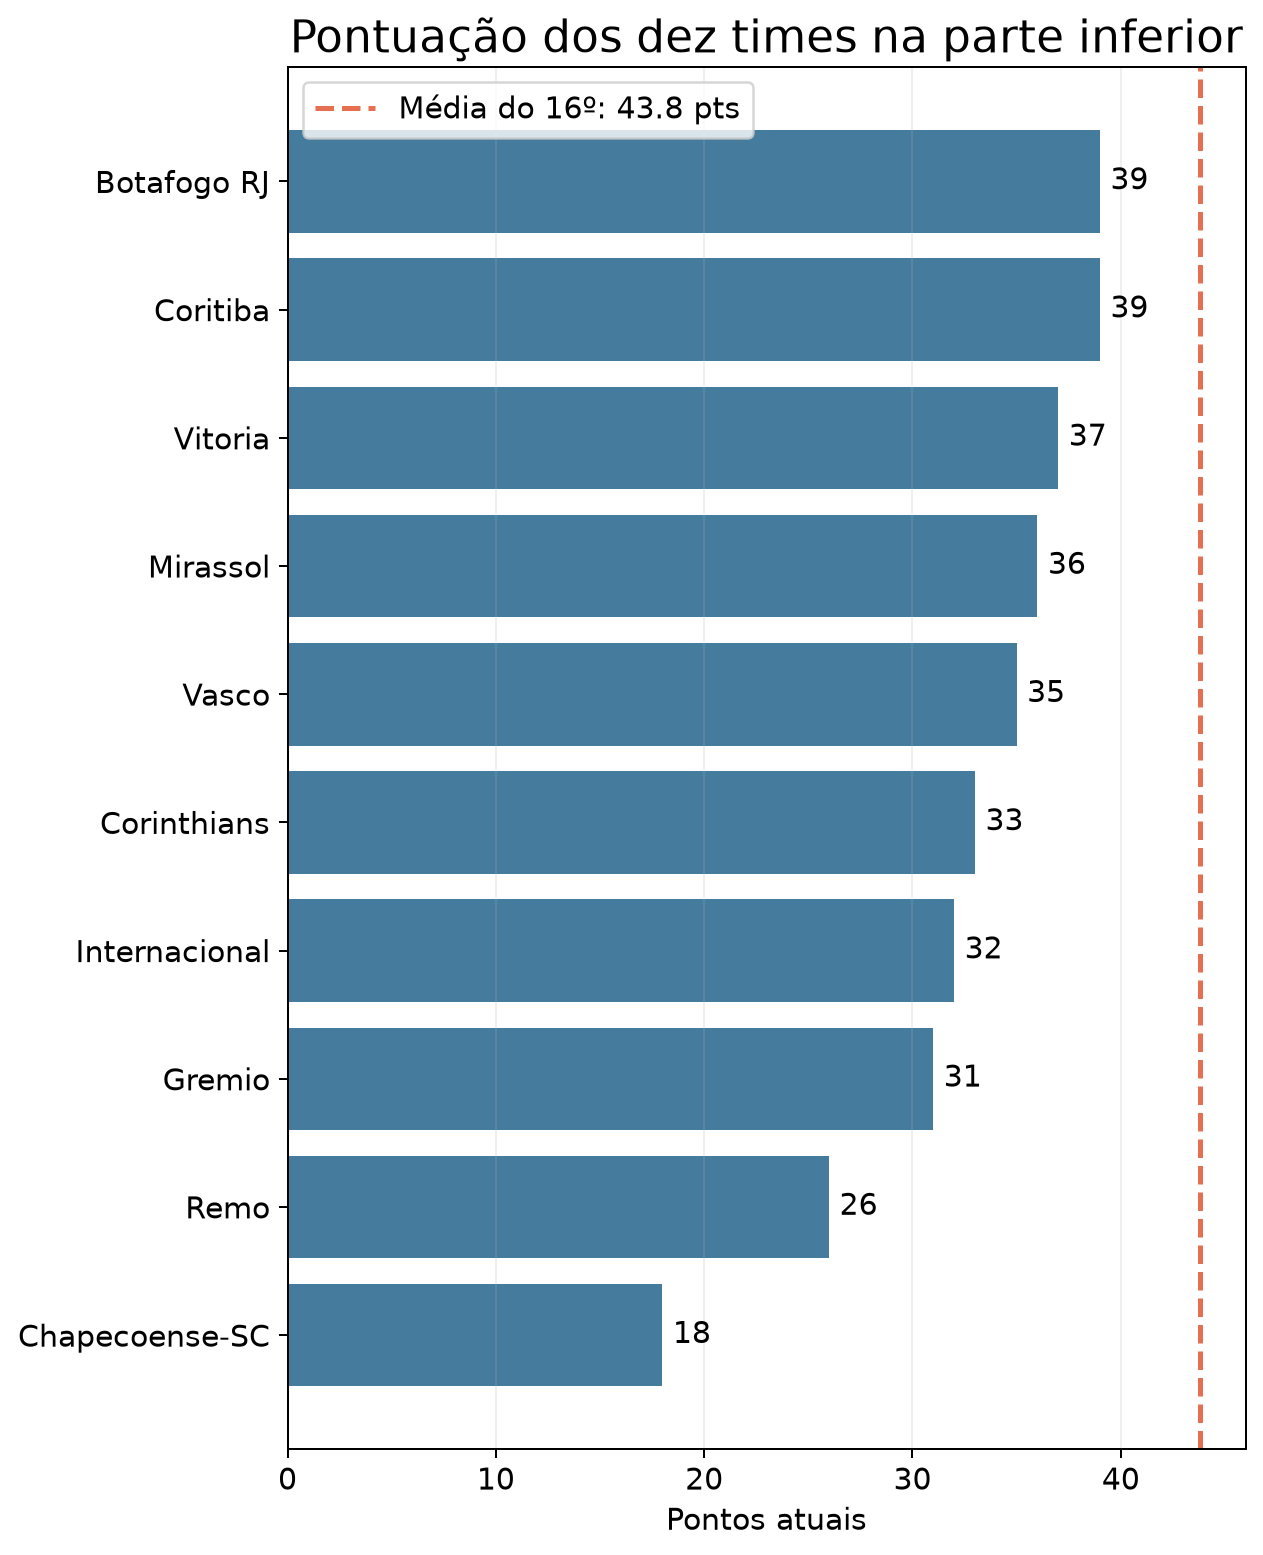

In [8]:
bottom = mart_table.sort_values('position').tail(10).copy()
fig = px.bar(bottom, x='team', y='points', color='position',
    hover_data=['played', 'wins', 'goal_difference'], color_continuous_scale='Blues_r',
    labels={'team':'Time', 'points':'Pontos atuais', 'position':'Posição'},
    title='Pontuação atual dos 10 times na parte inferior da tabela', template='plotly_white')
fig.add_hline(y=safe_avg, line_dash='dash', line_color='#d62728',
    annotation_text=f'Média histórica do 16º salvo: {safe_avg:.1f} pts')
fig.update_layout(height=500, xaxis_tickangle=-35, coloraxis_showscale=False)
fig.show()
display(Image(filename=str(EXPORT_DIR / '05_pontos_vs_referencia.png')))


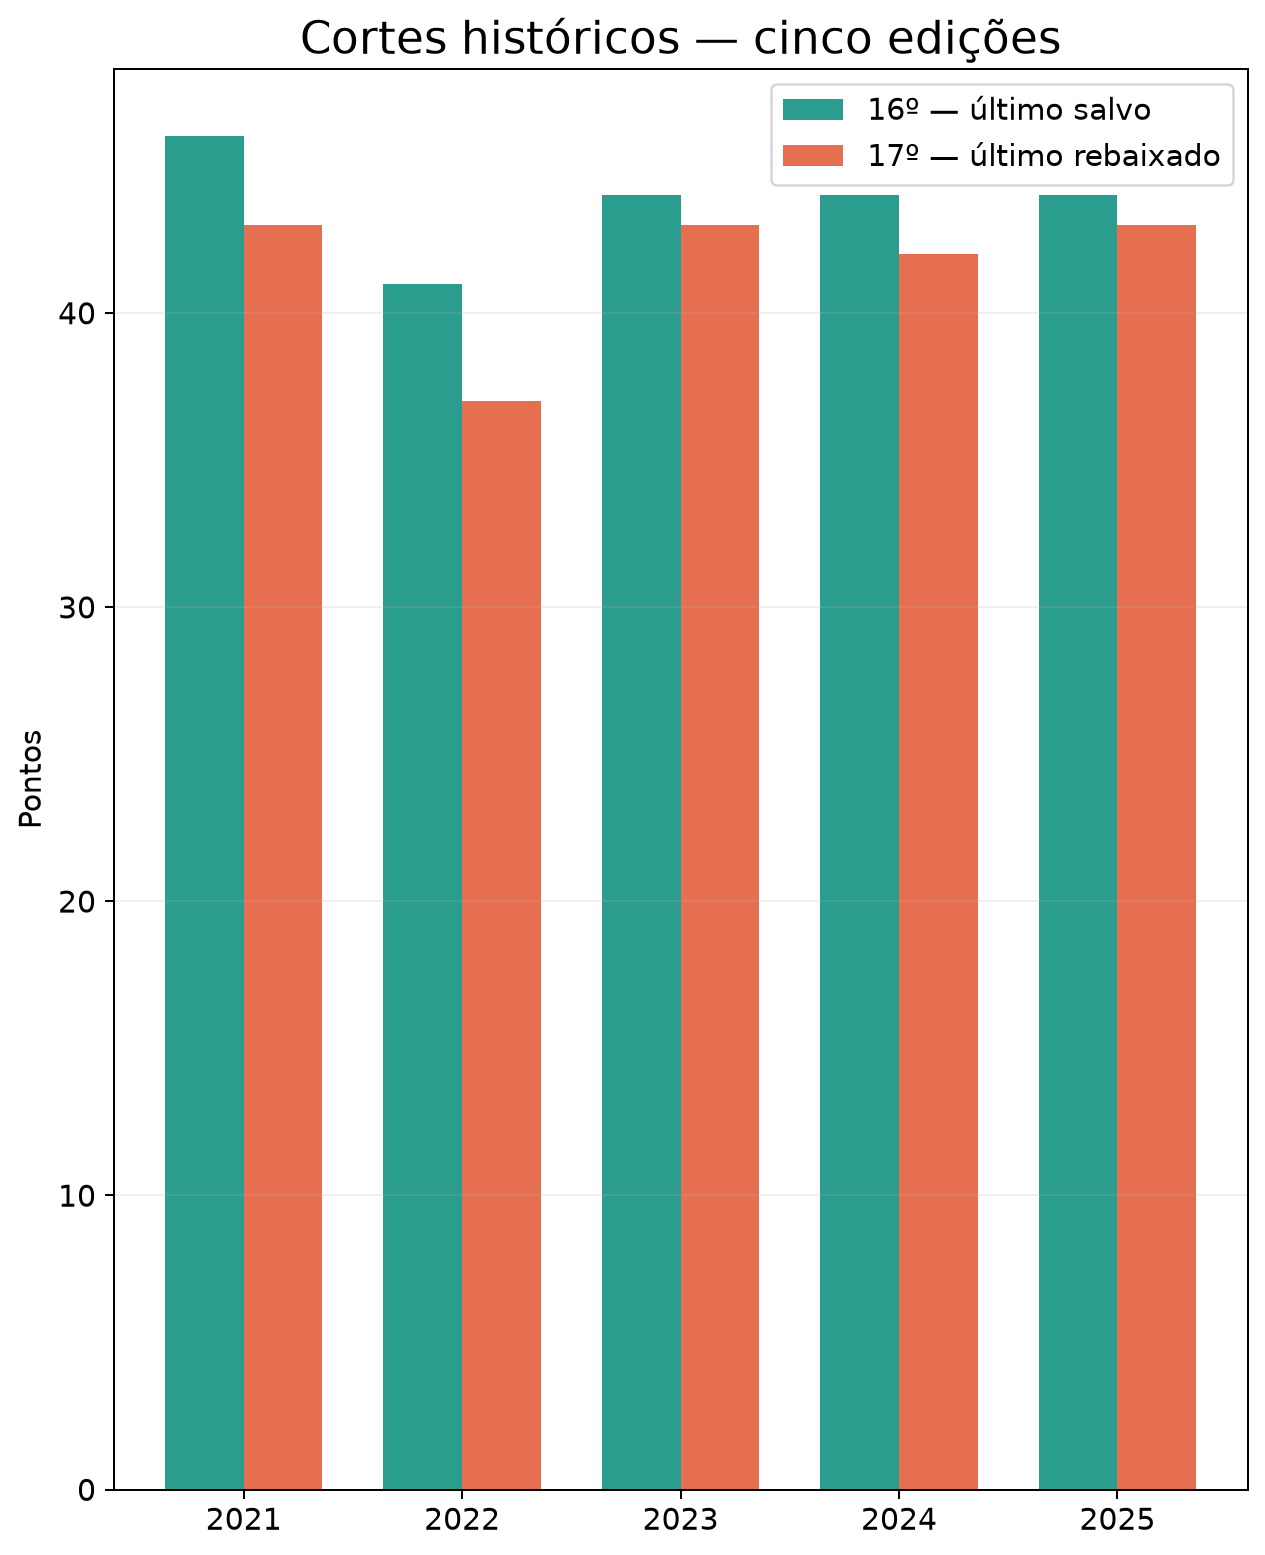

In [9]:
cutoff = thresholds.melt(id_vars='season',
    value_vars=['last_safe_points', 'last_relegated_points'], var_name='cutoff', value_name='points')
cutoff['cutoff'] = cutoff['cutoff'].map({'last_safe_points':'16º — salvo', 'last_relegated_points':'17º — último rebaixado'})
fig = px.bar(cutoff, x='season', y='points', color='cutoff', barmode='group', text='points',
    labels={'season':'Temporada', 'points':'Pontos', 'cutoff':'Corte'},
    title='Pontos de corte nas cinco edições completas anteriores', template='plotly_white',
    color_discrete_map={'16º — salvo':'#2a9d8f', '17º — último rebaixado':'#e76f51'})
fig.update_layout(height=450)
fig.show()
display(Image(filename=str(EXPORT_DIR / '03_cortes_historicos.png')))


,Temporada,Time rebaixado,Posição,Pontos
0,2025,Ceara,17,43.0
1,2025,Fortaleza,18,43.0
2,2025,Juventude,19,35.0
3,2025,Sport Recife,20,17.0
4,2024,Athletico-PR,17,42.0
5,2024,Criciuma,18,38.0
6,2024,Atletico GO,19,30.0
7,2024,Cuiaba,20,30.0
8,2023,Santos,17,43.0
9,2023,Goias,18,38.0


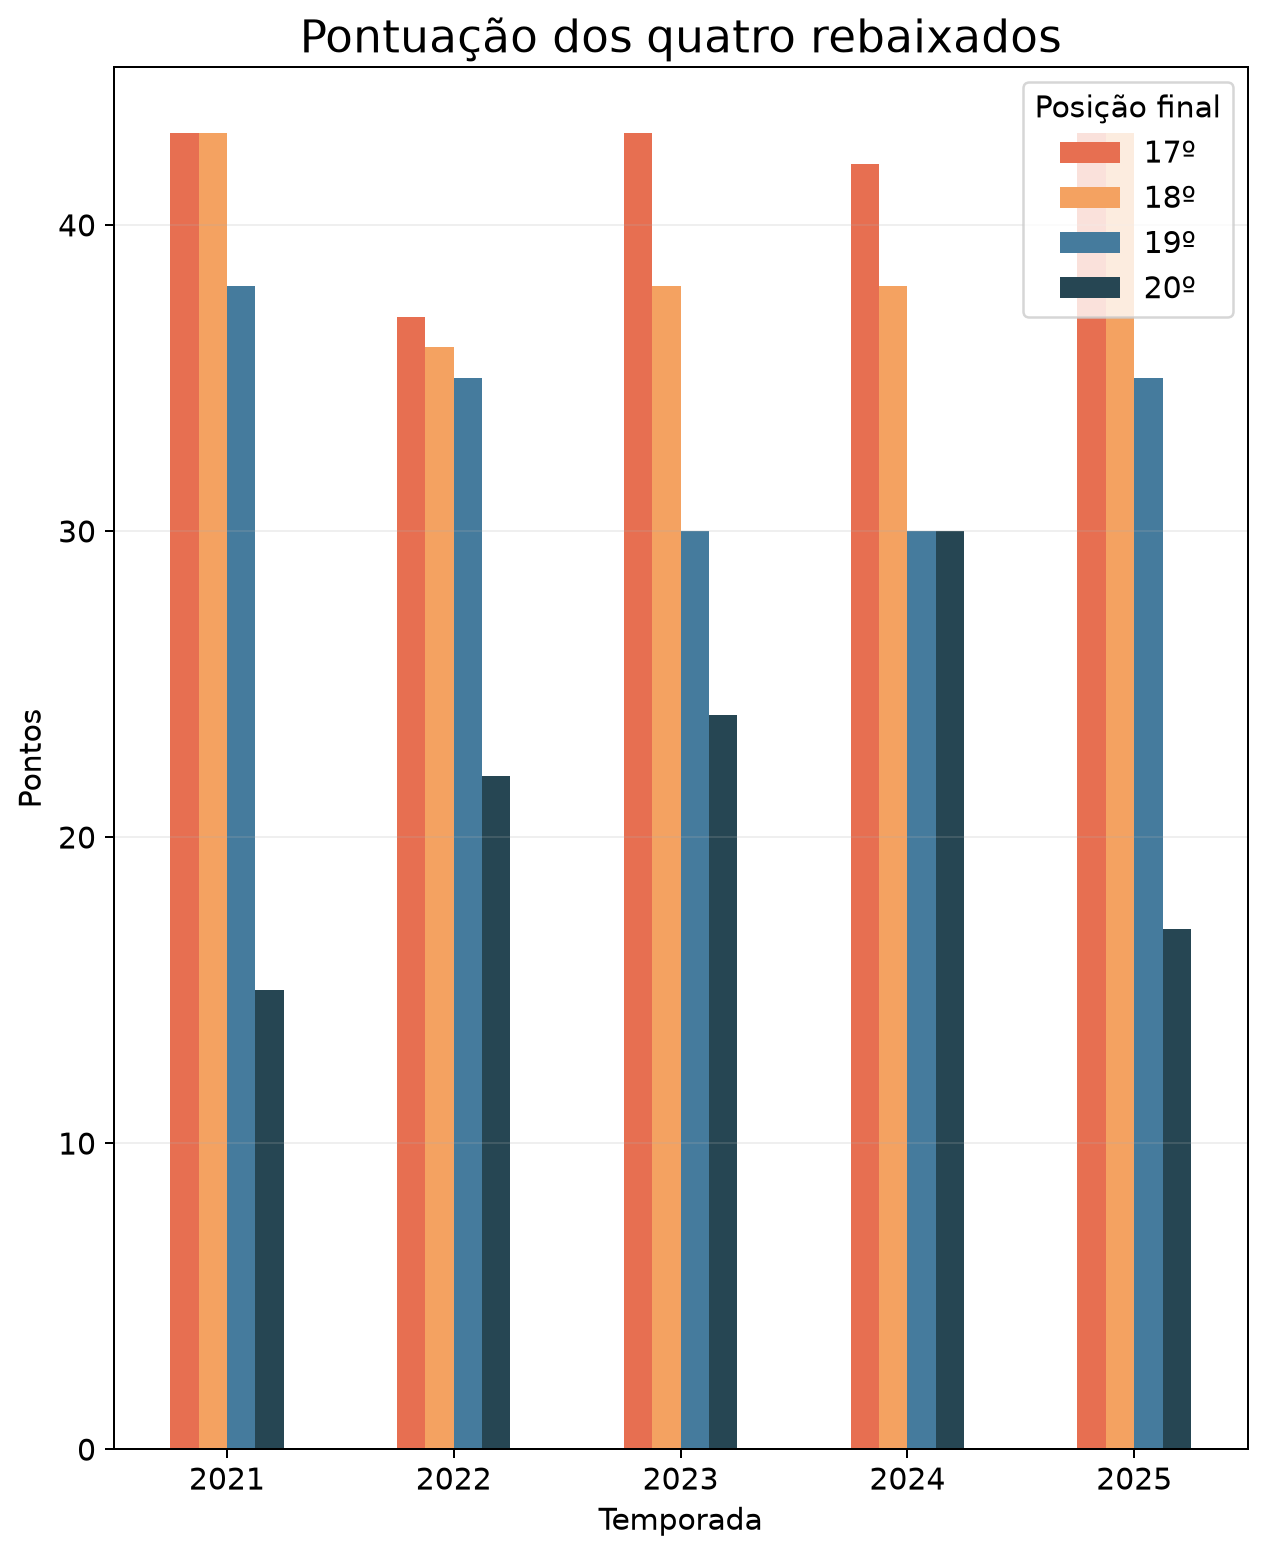

In [10]:
fig = px.bar(relegated, x='season', y='points', color='final_position', barmode='group',
    hover_name='relegated_team', text='points', category_orders={'final_position':[17,18,19,20]},
    labels={'season':'Temporada', 'points':'Pontos', 'final_position':'Posição final'},
    title='Pontos dos quatro clubes rebaixados por temporada', template='plotly_white')
fig.update_layout(height=500)
fig.show()
display(relegated.rename(columns={'season':'Temporada','relegated_team':'Time rebaixado','final_position':'Posição','points':'Pontos'}))
display(Image(filename=str(EXPORT_DIR / '04_pontos_rebaixados.png')))


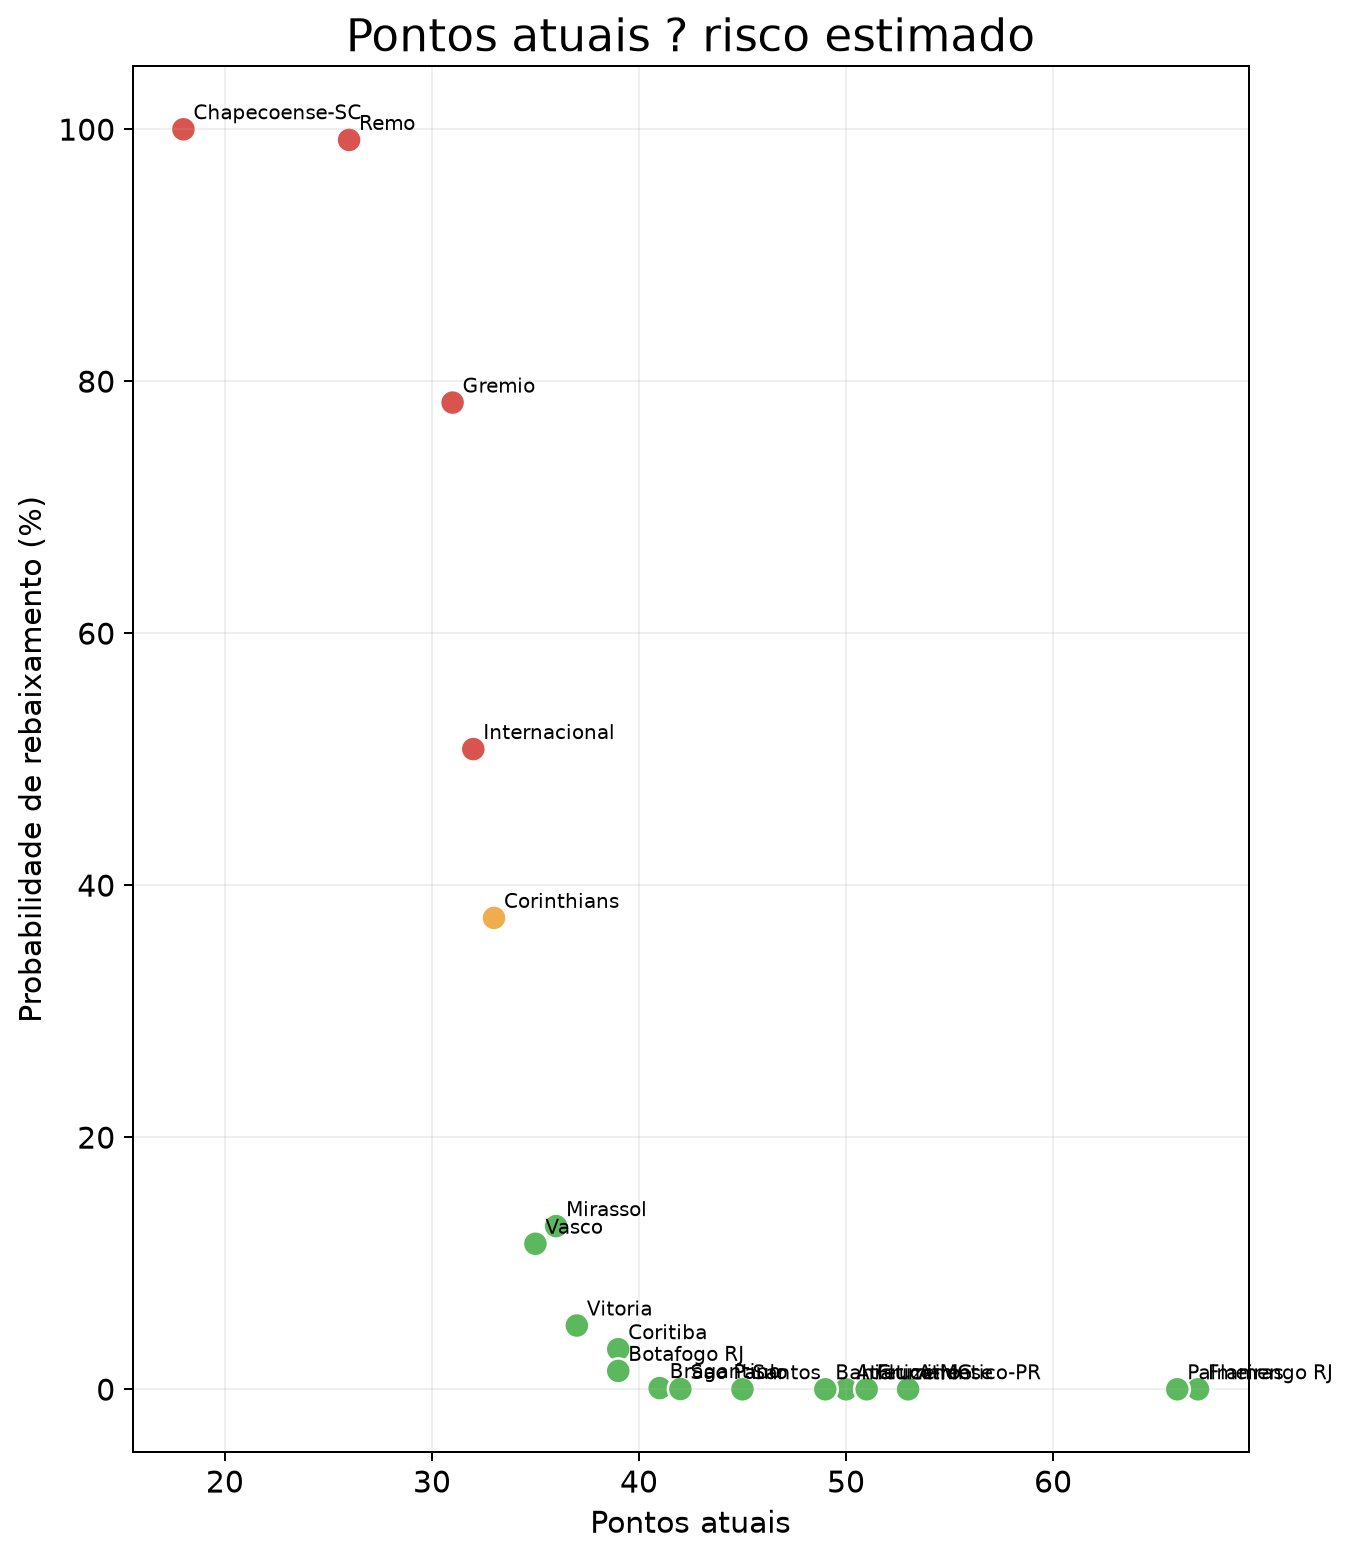

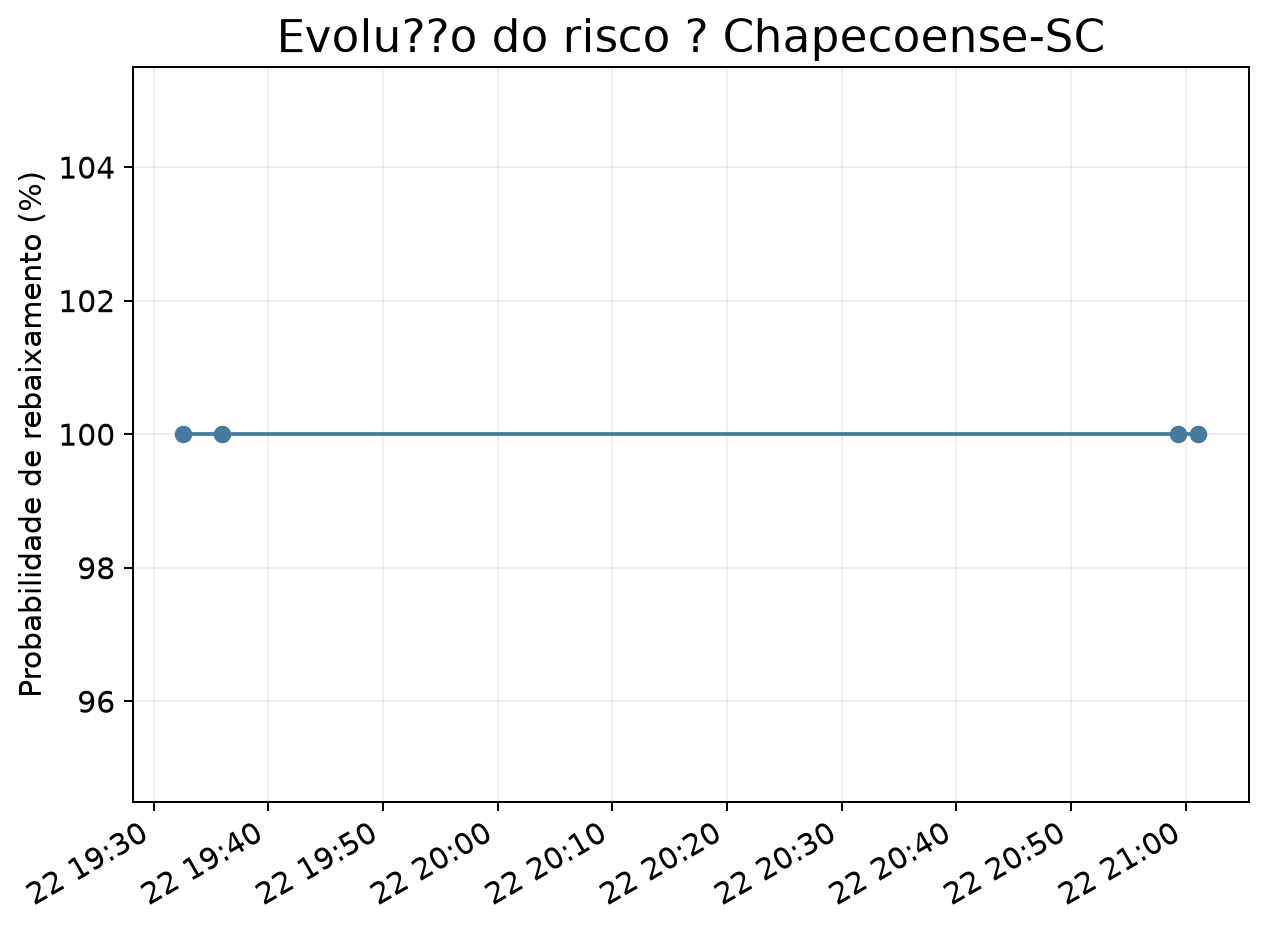

In [11]:
fig = px.scatter(risk, x='points', y='relegation_probability', color='position', size='simulations',
    hover_name='team', text='team', color_continuous_scale='Turbo',
    labels={'points':'Pontos atuais','relegation_probability':'Probabilidade de rebaixamento','position':'Posição'},
    title='Pontos atuais × probabilidade simulada', template='plotly_white')
fig.update_traces(textposition='top center', textfont_size=9)
fig.update_layout(height=600, yaxis_tickformat='.0%')
fig.show()

team = risk.iloc[0]['team']
series = risk_history.loc[risk_history['team'].eq(team)].sort_values('estimated_at')
if len(series) > 1:
    fig = px.line(series, x='estimated_at', y='relegation_probability', markers=True,
        title=f'Evolução do risco estimado — {team}',
        labels={'estimated_at':'Data da execução','relegation_probability':'Probabilidade'}, template='plotly_white')
    fig.update_layout(height=400, yaxis_tickformat='.0%')
    fig.show()
else:
    print('Existe um snapshot; a série histórica aumenta a cada atualização do pipeline.')
display(Image(filename=str(EXPORT_DIR / '06_pontos_vs_risco.png')))
if (EXPORT_DIR / '07_evolucao_risco.png').exists():
    display(Image(filename=str(EXPORT_DIR / '07_evolucao_risco.png')))


## Interpretação e limitações
- A média histórica do 16º lugar é uma referência, não uma meta garantida.
- Os 71 confrontos de 2026 são inferidos pelo turno e returno; o arquivo não contém datas futuras.
- A simulação usa quatro rebaixados e trata jogos como independentes.
- Para executar: na raiz do repositório rode `jupyter lab notebooks/bra_2026_analise.ipynb`. O notebook precisa de `BRA.csv` e `warehouse/football.duckdb`; atualize os dados com `py -3.14 -m src.run_pipeline`.